# Step 2 – Exploring the relations in UR3 CobotOps

Goal: visualise the relations that matter for **grip-loss prediction** before building the benchmark.
Each cell answers one question. Vocabulary:
- **cycle**: one repetition of the pick-and-place task (≈ 25 s). Identified by a *change* of the `cycle` counter (the counter goes back from 232 to 224 once, so its values are not unique).
- **event / onset**: a grip loss spans several consecutive seconds (an *event*); its **onset** is its first second.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 4)

# French CSV format: ';' separates columns, ',' is the decimal separator
df = pd.read_csv("UR3CobotOps.csv", sep=";", decimal=",")
df.head()
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 7409 entries, 0 to 7408
Data columns (total 35 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Num                   7409 non-null   int64  
 1   Timestamp             7409 non-null   str    
 2   Current_J0            7363 non-null   float64
 3   Temperature_T0        7355 non-null   float64
 4   Current_J1            7355 non-null   float64
 5   Temperature_J1        7355 non-null   float64
 6   Current_J2            7355 non-null   float64
 7   Temperature_J2        7355 non-null   float64
 8   Current_J3            7355 non-null   float64
 9   Temperature_J3        7355 non-null   float64
 10  Current_J4            7355 non-null   float64
 11  Temperature_J4        7355 non-null   float64
 12  Current_J5            7355 non-null   float64
 13  Temperature_J5        7355 non-null   float64
 14  Speed_J0              7355 non-null   float64
 15  Speed_J1              7355 non-n

,Num,Current_J0,Temperature_T0,Current_J1,Temperature_J1,Current_J2,Temperature_J2,Current_J3,Temperature_J3,Current_J4,...,Unnamed: 25,Unnamed: 26,Unnamed: 27,Unnamed: 28,Unnamed: 29,Unnamed: 30,Unnamed: 31,Unnamed: 32,Unnamed: 33,Unnamed: 34
count,7409.000000,7363.000000,7355.000000,7355.000000,7355.000000,7355.000000,7355.000000,7355.000000,7355.000000,7355.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
mean,3705.000000,-0.048934,34.906781,-2.297936,37.659636,-1.199381,38.064064,-0.605312,40.936999,-0.022968,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,2138.938405,0.829395,2.762057,0.800450,3.247315,0.609984,3.311948,0.514937,3.182399,0.630789,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1.000000,-6.247756,27.812500,-5.808734,29.312500,-4.171966,29.375000,-3.333102,32.125000,-4.738406,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,1853.000000,-0.195026,33.000000,-2.664919,35.375000,-1.552803,35.750000,-0.830933,38.937500,-0.125809,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,3705.000000,-0.080830,36.500000,-2.236342,39.687500,-1.077137,40.187500,-0.571190,43.062500,-0.012325,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,5557.000000,0.095959,37.062500,-1.778334,40.125000,-0.838721,40.437500,-0.388398,43.125000,0.086098,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
max,7409.000000,6.806938,37.250000,1.083596,40.500000,2.464940,40.937500,2.270268,43.437500,4.089389,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 1. Load and clean

In [2]:

df = df.loc[:, ~df.columns.str.startswith("Unnamed")]        # empty trailing columns
df.columns = df.columns.str.strip()                           # 'cycle ' -> 'cycle'
df = df.rename(columns={"Temperature_T0": "Temperature_J0"})  # T0 is joint J0

df["ts"] = pd.to_datetime(df["Timestamp"].str.strip('"'), utc=True)  # 863 quoted timestamps
df["GL"] = df["grip_lost"].eq("VRAI").astype(int)
df["PS"] = df["Robot_ProtectiveStop"].map({"VRAI": 1, "FAUX": 0})    # NaN on the 54 empty rows
df["nan_row"] = df["Current_J1"].isna()

CUR = [f"Current_J{i}" for i in range(6)] # all sensors of the dataset (current,temperature and speed of the joints)
TEM = [f"Temperature_J{i}" for i in range(6)]
SPD = [f"Speed_J{i}" for i in range(6)]
SENSORS = CUR + TEM + SPD + ["Tool_current"]
print(df.shape)
df[["ts", "cycle", "GL", "PS"] + SENSORS[:3]].head()

(7409, 28)


,ts,cycle,GL,PS,Current_J0,Current_J1,Current_J2
0,2022-10-26 08:17:21.847+00:00,1,0,0.0,0.109628,-2.024669,-1.531442
1,2022-10-26 08:17:22.852+00:00,1,0,0.0,0.595605,-2.278456,-0.866556
2,2022-10-26 08:17:23.857+00:00,1,0,0.0,-0.229474,-2.800408,-2.304336
3,2022-10-26 08:17:24.863+00:00,1,0,0.0,0.065053,-3.687768,-1.217652
4,2022-10-26 08:17:25.877+00:00,1,0,0.0,0.884140,-2.938830,-1.794076


In [3]:
# Structure of the time series
df["segment"]  = (df["ts"].diff().dt.total_seconds() > 5).cumsum()   # recording breaks
df["cycle_id"] = (df["cycle"] != df["cycle"].shift()).cumsum()       # unique cycle id
df["pos"]      = df.groupby("cycle_id").cumcount()                   # seconds since cycle start
df["onset"]    = (df["GL"] == 1) & (df["GL"].shift(fill_value=0) == 0)
df["event_id"] = df["onset"].cumsum().where(df["GL"] == 1)

print("segments (rows):", df.groupby("segment").size().tolist())
print("cycles:", df["cycle_id"].nunique(), "| grip-loss rows:", df["GL"].sum(),
      "| events:", df["onset"].sum())
d = df[~df["nan_row"]].copy()   # rows with sensor values, used for the statistics below

segments (rows): [1094, 72, 1703, 4540]
cycles: 249 | grip-loss rows: 243 | events: 77


## 1b. Recording period: one day, two sessions
All the data comes from **a single day**. The robot was recorded in a **morning** and an **afternoon** session, separated by a break of several hours with no data (times are in UTC).

In [4]:
import matplotlib.dates as mdates

print("Days in the dataset:", sorted(df["ts"].dt.date.unique()))

# A new session starts after a break of more than 1 hour
df["session"] = (df["ts"].diff() > pd.Timedelta(hours=1)).cumsum().map({0: "morning", 1: "afternoon"})

sessions = df.groupby("session", sort=False).agg(
    start=("ts", "min"), end=("ts", "max"), rows=("ts", "size"),
    grip_loss_events=("onset", "sum"))
sessions["duration"] = sessions["end"] - sessions["start"]
sessions["events_per_hour"] = (sessions["grip_loss_events"]
                               / (sessions["duration"].dt.total_seconds() / 3600)).round(1)
lunch_break = sessions.loc["afternoon", "start"] - sessions.loc["morning", "end"]
print("Break between the sessions:", lunch_break)
sessions

Days in the dataset: [datetime.date(2022, 10, 26)]
Break between the sessions: 0 days 05:13:34.125000


,start,end,rows,grip_loss_events,duration,events_per_hour
session,,,,,,
morning,2022-10-26 08:17:21.847+00:00,2022-10-26 09:06:19.201+00:00,2869,34,0 days 00:48:57.354000,41.7
afternoon,2022-10-26 14:19:53.326+00:00,2022-10-26 15:36:06.580+00:00,4540,43,0 days 01:16:13.254000,33.8


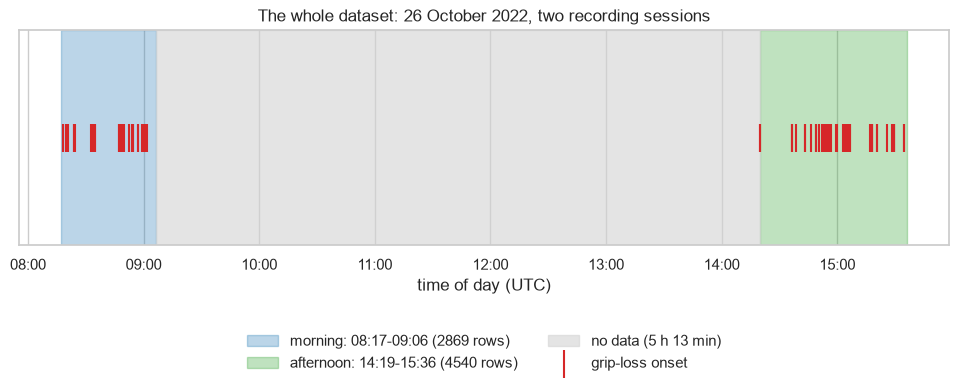

In [5]:
fig, ax = plt.subplots(figsize=(12, 2.8))
colors = {"morning": "tab:blue", "afternoon": "tab:green"}
for name, s in sessions.iterrows():
    ax.axvspan(s["start"], s["end"], color=colors[name], alpha=.3,
               label=f"{name}: {s['start']:%H:%M}-{s['end']:%H:%M} ({s['rows']} rows)")
ax.axvspan(sessions.loc["morning", "end"], sessions.loc["afternoon", "start"],
           color="lightgray", alpha=.6, label=f"no data ({lunch_break.seconds // 3600} h {lunch_break.seconds % 3600 // 60} min)")

ons = df[df["onset"]]
ax.scatter(ons["ts"], np.full(len(ons), .5), marker="|", s=400, color="tab:red", label="grip-loss onset")

ax.set_yticks([])
ax.xaxis.set_major_locator(mdates.HourLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.set_xlabel("time of day (UTC)")
ax.set_title(f"The whole dataset: {df['ts'].dt.date.iloc[0]:%d %B %Y}, two recording sessions")
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.35), ncol=2, frameon=False)
plt.show()

**Reading:** the whole dataset is **one day** (26 October 2022) and only **~2 h of actual recording**: 49 min in the morning (2,869 rows) and 1 h 16 min in the afternoon (4,540 rows), separated by 5 h 13 min without data. Grip losses happen in both sessions, a bit more often per hour in the morning (≈ 42/h vs ≈ 34/h).

*Implications:* the model only sees **one robot, one task, one day**, so it cannot learn day-to-day variations and its generalisation is limited. Windows and lags must never be computed across the break, and the two sessions start in different thermal states (cold vs warm robot).

## 2. Time: is the grip-loss rate stable during the day?
Temperatures rise while the robot warms up. If grip losses are more frequent at some moments, any variable that follows time (temperatures, cycle counter) will *look* predictive.

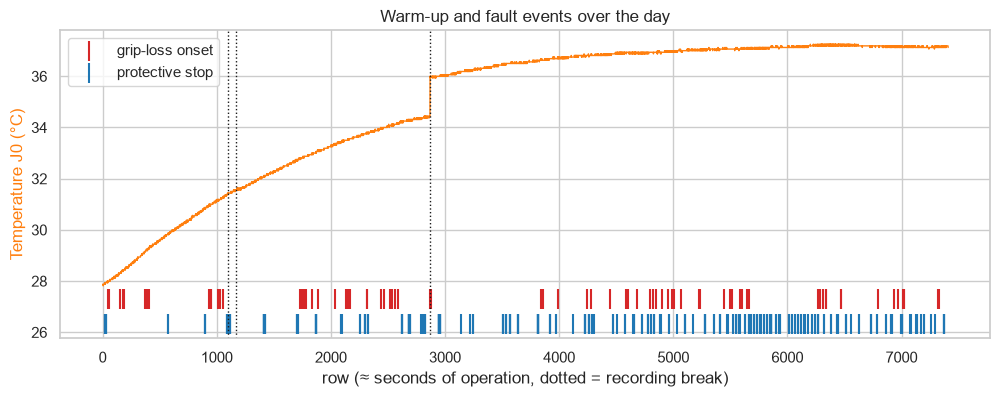

In [6]:
# x axis = row number (≈ seconds of operation), so the 5 h lunch gap is not drawn
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(d.index, d["Temperature_J0"], color="tab:orange", lw=1)
ax.set_ylabel("Temperature J0 (°C)", color="tab:orange")
low = d["Temperature_J0"].min()
ons, ps = d[d["onset"]], d[d["PS"] == 1]
ax.scatter(ons.index, np.full(len(ons), low - 0.5), marker="|", s=200, color="tab:red", label="grip-loss onset")
ax.scatter(ps.index, np.full(len(ps), low - 1.5), marker="|", s=200, color="tab:blue", label="protective stop")
for b in df.index[df["segment"].diff() > 0]:
    ax.axvline(b, color="k", ls=":", lw=1)   # recording breaks
ax.set_xlabel("row (≈ seconds of operation, dotted = recording break)")
ax.legend(loc="upper left"); ax.set_title("Warm-up and fault events over the day")
plt.show()

**Reading:** the temperature (orange) rises quickly in the morning (28 → 34 °C), jumps to 36 °C after the break (the robot kept warm or ran in between), then levels off around 37 °C. Grip losses (red) are dense at the very beginning of the morning, rare just after the break, then frequent again in the afternoon. Protective stops (blue) become much more frequent in the afternoon (21 episodes in the morning vs 87 in the afternoon).

*Implications:* the robot is not in a steady state: the start of the day is a regime of its own. The two faults do not follow the same timeline, which already suggests they are unrelated (confirmed in section 8). The chronological test period (end of the afternoon) will be a warm, stable robot.

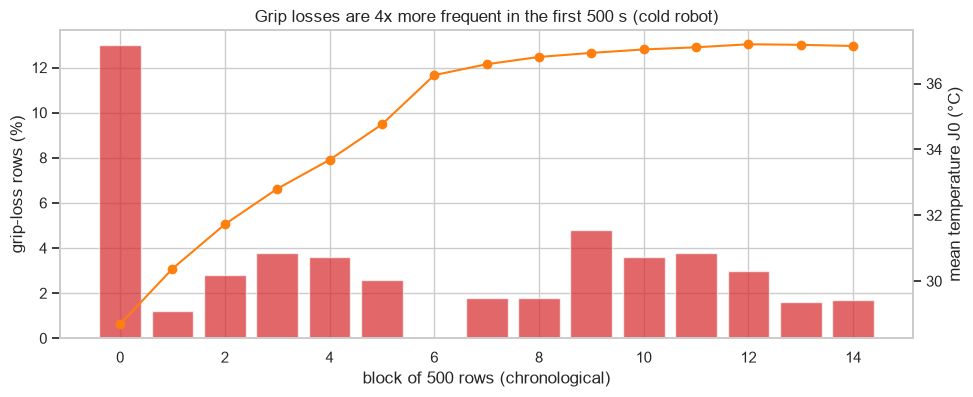

In [7]:
# Grip-loss rate and mean temperature per block of 500 seconds
blocks = d.groupby(np.arange(len(d)) // 500).agg(gl_rate=("GL", "mean"),
                                                   temp=("Temperature_J0", "mean"))
fig, ax = plt.subplots()
ax.bar(blocks.index, blocks["gl_rate"] * 100, color="tab:red", alpha=.7)
ax.set_xlabel("block of 500 rows (chronological)"); ax.set_ylabel("grip-loss rows (%)")
ax2 = ax.twinx(); ax2.plot(blocks.index, blocks["temp"], "o-", color="tab:orange")
ax2.set_ylabel("mean temperature J0 (°C)"); ax2.grid(False)
ax.set_title("Grip losses are 4x more frequent in the first 500 s (cold robot)")
plt.show()

**Reading:** ~13 % of the rows are grip losses in the first 500 s, against 1–5 % afterwards, and 0 % in block 6 (just after the break). During the same first block the robot is at its coldest.

*Implications:* this is **confounding**: "cold robot" and "start of the session" happen together, so we cannot tell whether temperature causes grip losses or whether something else happens at start-up (settings, first parts). A model using temperature will mostly learn "it is the start of the day". Temperature features must be tested with and without, and the result must not be read as a causal effect.

## 3. Redundancy between sensors

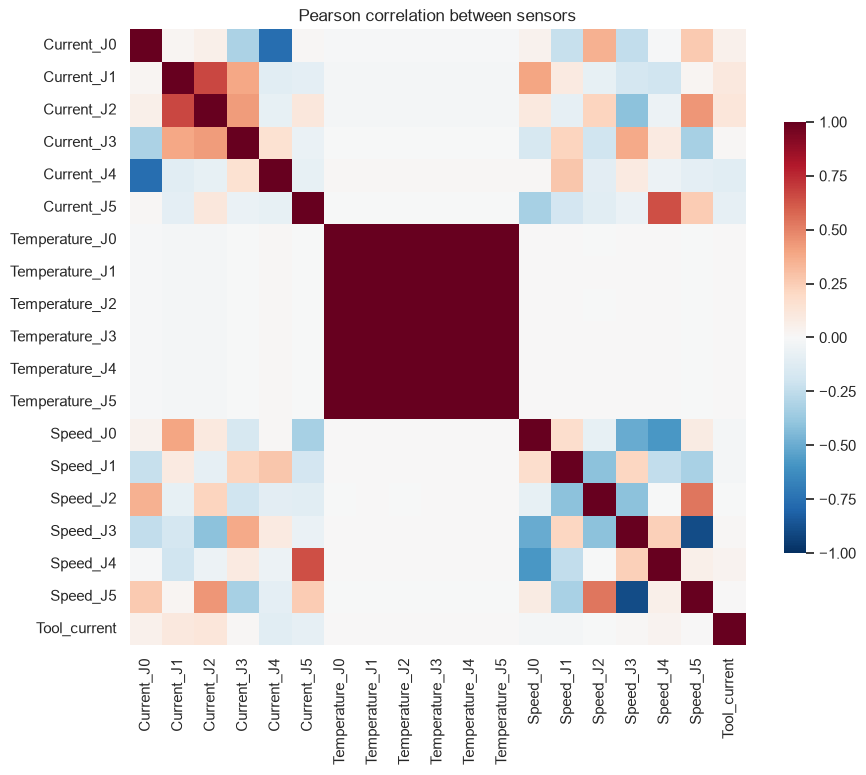

min correlation between the 6 temperatures: 0.993


In [8]:
corr = d[SENSORS].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True,
            cbar_kws={"shrink": .7})
plt.title("Pearson correlation between sensors")
plt.show()
print("min correlation between the 6 temperatures:",
      round(corr.loc[TEM, TEM].values.min(), 3))

**Reading:**
- the **6 temperatures form one dark-red block** (r ≥ 0.99): they all measure the same thing, the global warm-up of the robot;
- a few mechanical couplings: Current_J0 / Current_J4 ≈ −0.75, Current_J1 / Current_J2 ≈ +0.6, Speed_J3 / Speed_J5 ≈ −0.9, Current_J5 / Speed_J4 ≈ +0.6 (joints that move together or compensate each other);
- **Tool_current is correlated with nothing**.

*Implications:* keep **one** temperature (or their mean) to remove redundancy; it matters for linear models (logistic regression, SVM) which suffer from multicollinearity, much less for trees. The other couplings are partial (|r| < 0.9), so these currents and speeds carry different information and are all kept.

## 4. Which signals differ during a grip loss, and which ones announce it?
No model is trained here. For each sensor taken alone, the **univariate AUC** is the probability that a random positive row has a higher value than a random negative row (0.5 = no difference; far from 0.5, up or down = discriminant). It is the ROC AUC obtained by using the raw sensor value as a score (`roc_auc_score`, equivalent to the Mann-Whitney U statistic divided by the number of pairs).

We compute it three times:
1. **during the loss**: rows with `GL == 1` vs rows with `GL == 0` (what happens *while* the part is lost);
2. **before**: the real prediction target: a row is positive if a grip loss **starts within the next N = 3 s**; rows where a loss is already ongoing are removed;
3. **before, adjusted**: same target, but on the deviation from the **normal cycle profile** at the same position (removes the "moment of the cycle" effect).

A sensor that is strong *during* but weak *before* only describes the **consequences** of the loss: using it would be leakage.

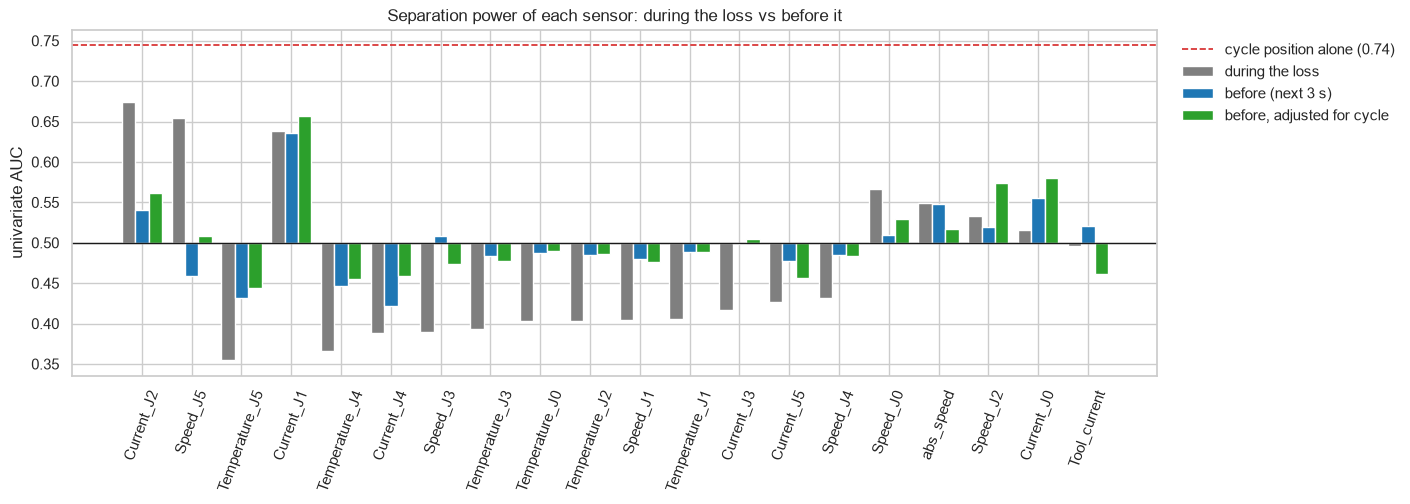

,during the loss,before (next 3 s),"before, adjusted for cycle"
Current_J2,0.674,0.541,0.561
Speed_J5,0.654,0.458,0.508
Temperature_J5,0.355,0.431,0.444
Current_J1,0.638,0.636,0.657
Temperature_J4,0.366,0.447,0.455
Current_J4,0.388,0.422,0.458
Speed_J3,0.390,0.509,0.474
Temperature_J3,0.393,0.484,0.478
Temperature_J0,0.403,0.488,0.490
Temperature_J2,0.404,0.485,0.486


In [9]:
from sklearn.metrics import roc_auc_score

d["abs_speed"] = d[SPD].abs().sum(axis=1)
FEATS = SENSORS + ["abs_speed"]
N = 3   # horizon in seconds

# Prediction target: 1 if a grip loss starts at t+1 ... t+N (computed on the full series)
df["y_next"] = pd.concat([df["onset"].shift(-k, fill_value=False) for k in range(1, N + 1)],
                         axis=1).any(axis=1).astype(int)
d["y_next"] = df.loc[d.index, "y_next"]
before = d[d["GL"] == 0]                          # drop the rows where a loss is ongoing

# Normal profile: mean value at each cycle position, in cycles without any grip loss
gl_cycles = set(d.loc[d["GL"] == 1, "cycle_id"])
profile = d[~d["cycle_id"].isin(gl_cycles)].groupby("pos")[FEATS].mean()
deviation = before[FEATS] - profile.reindex(before["pos"]).to_numpy()

def auc(y, x):
    keep = x.notna()                              # positions never seen in normal cycles
    return roc_auc_score(y[keep], x[keep])

res = pd.DataFrame({
    "during the loss":            {f: auc(d["GL"], d[f]) for f in FEATS},
    f"before (next {N} s)":       {f: auc(before["y_next"], before[f]) for f in FEATS},
    "before, adjusted for cycle": {f: auc(before["y_next"], deviation[f]) for f in FEATS},
})
res = res.loc[(res["during the loss"] - .5).abs().sort_values(ascending=False).index]

# Reference: the cycle position alone (grip-loss rate per position, in-sample -> optimistic)
pos_rate = before.groupby("pos")["y_next"].mean()
auc_position = auc(before["y_next"], before["pos"].map(pos_rate))

x, w = np.arange(len(res)), .27
fig, ax = plt.subplots(figsize=(14, 4.5))
for k, (col, color) in enumerate(zip(res.columns, ["tab:gray", "tab:blue", "tab:green"])):
    ax.bar(x + (k - 1) * w, res[col] - .5, w, bottom=.5, color=color, label=col)
ax.axhline(.5, color="k", lw=1)
ax.axhline(auc_position, color="tab:red", ls="--", lw=1.2,
           label=f"cycle position alone ({auc_position:.2f})")
ax.set_xticks(x, res.index, rotation=70)
ax.set_ylabel("univariate AUC")
ax.set_title("Separation power of each sensor: during the loss vs before it")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
plt.show()
res.round(3)

**Reading:** compare the grey bar (*during*) with the blue and green bars (*before*):
- **Speed_J5** (0.65 during → 0.46 before → 0.51 adjusted) and **Current_J2** (0.67 → 0.54 → 0.56) look like the best sensors *during* the loss, but most of their signal **disappears before it**: they mainly describe the **consequences** of the loss (the arm moving without its part). This is the leakage that the "predict before the onset" design avoids;
- **Current_J1** is the only sensor that keeps its signal before the loss (0.64 during → 0.64 before → 0.66 adjusted): a **real precursor**, consistent with section 6 and with the mechanics (the shoulder carries the part);
- the **temperatures** move towards 0.5 (0.36–0.40 during → 0.43–0.49 before): their apparent effect was mostly the start-of-day effect;
- **Current_J4** loses most of its effect once the cycle position is removed (0.39 → 0.46): it only reflected *when* in the cycle losses happen;
- **Tool_current** stays close to 0.5 in all three versions.

The red dashed line is the **cycle position alone** (grip-loss rate per position): ≈ 0.74, **higher than any single sensor** before the loss (max ≈ 0.66). It is computed in-sample, so slightly optimistic, but the gap is clear.

*Implications:* the "during" ranking must not be used to choose features. No sensor alone anticipates the losses well; the models will have to **combine** sensors and the cycle position, and they must beat the cycle-position baseline to show any added value. Current_J1 (and its deviation from the normal profile) is the most promising input.

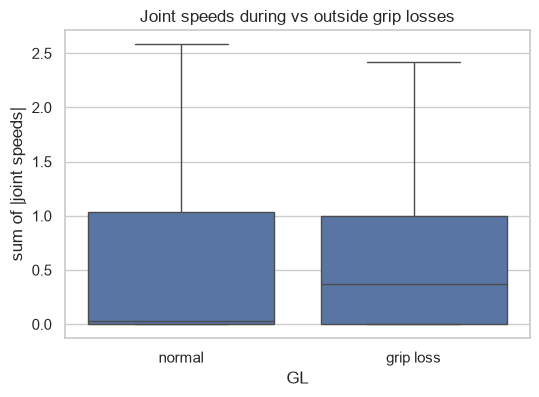

GL
0    0.031995
1    0.371005
Name: abs_speed, dtype: float64


In [10]:
# Joint speeds during vs outside grip losses
plt.figure(figsize=(6, 4))
sns.boxplot(data=d, x="GL", y="abs_speed", showfliers=False)
plt.xticks([0, 1], ["normal", "grip loss"]); plt.ylabel("sum of |joint speeds|")
plt.title("Joint speeds during vs outside grip losses")
plt.show()
print(d.groupby("GL")["abs_speed"].median())

**Reading:** the median of the summed joint speeds goes from ≈ 0.03 (normal) to ≈ 0.37 (grip loss), but **the two boxes overlap almost entirely** (0 to ~1 in both cases). The robot is stopped about half of the time in both groups; this is why the normal median is close to 0.

*Implications:* speed alone is a **weak** signal (AUC of abs_speed ≈ 0.55). The leakage risk (detecting the consequences of the loss instead of anticipating it) is mainly carried by the currents J1/J2, which change strongly when the part is no longer carried. In every case we predict **before the onset** and drop the rows where a loss is ongoing.

## 5. Position in the cycle

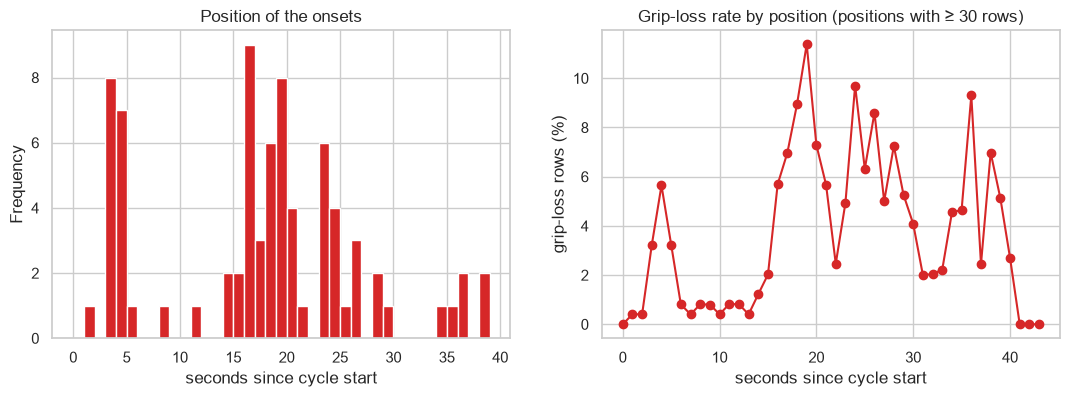

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
d.loc[d["onset"], "pos"].plot.hist(bins=range(0, 40), ax=axes[0], color="tab:red")
axes[0].set_xlabel("seconds since cycle start"); axes[0].set_title("Position of the onsets")

rate = d.groupby("pos")["GL"].agg(["mean", "size"]).query("size >= 30")
axes[1].plot(rate.index, rate["mean"] * 100, "o-", color="tab:red")
axes[1].set_xlabel("seconds since cycle start"); axes[1].set_ylabel("grip-loss rows (%)")
axes[1].set_title("Grip-loss rate by position (positions with ≥ 30 rows)")
plt.show()

**Reading:**
- *left*: the onsets have **two peaks** in the cycle: around **3–5 s** (~15 onsets) and between **15 and 21 s**, with a tail at 23–27 s and 35–39 s;
- *right*: the grip-loss rate is very low between 6 and 14 s (< 1 %) and reaches ~11 % around 19 s.

*Implications:* the risk depends strongly on the phase of the task. Two hypotheses for the early peak: a second risky phase (e.g. the grasp itself), or a counter artefact (if the cycle counter increments before the physical end of the task, a loss "at 4 s" is really the end of the previous cycle). The position-in-cycle baseline must therefore learn the **rate per position** on the training set, not a fixed 14–23 s window.

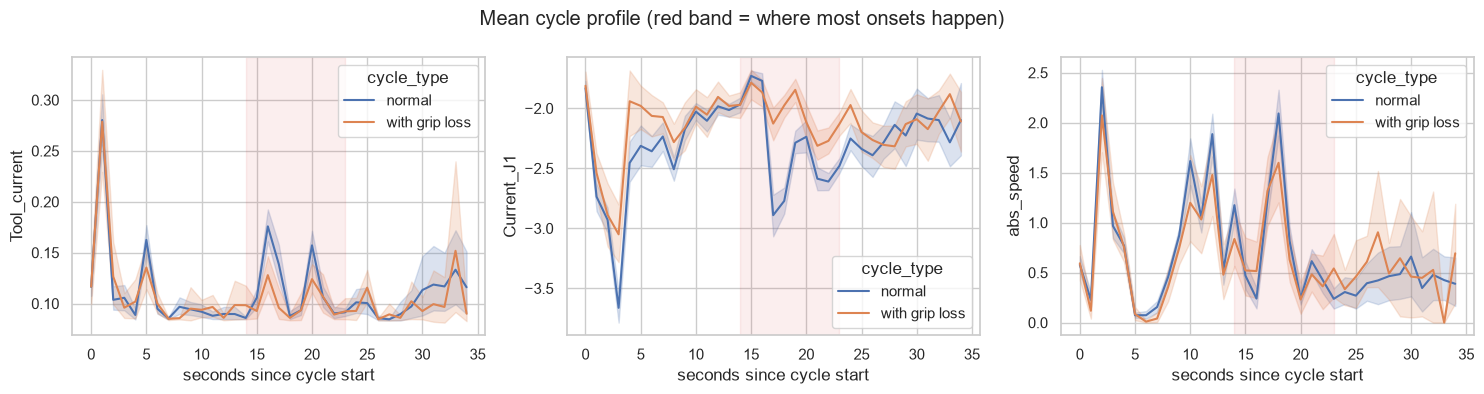

In [12]:
# Typical cycle profile: mean signal by position, cycles with vs without grip loss
gl_cycles = set(d.loc[d["GL"] == 1, "cycle_id"])
d["cycle_type"] = np.where(d["cycle_id"].isin(gl_cycles), "with grip loss", "normal")
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
for ax, col in zip(axes, ["Tool_current", "Current_J1", "abs_speed"]):
    sns.lineplot(data=d[d["pos"] < 35], x="pos", y=col, hue="cycle_type",
                 errorbar=("ci", 95), ax=ax)
    ax.axvspan(14, 23, color="tab:red", alpha=.08)
    ax.set_xlabel("seconds since cycle start")
fig.suptitle("Mean cycle profile (red band = where most onsets happen)")
plt.tight_layout(); plt.show()

**Reading:**
- **Tool_current** has peaks at 1, 5, 16 and 20 s (gripper opening/closing). In cycles with a grip loss, **the 16 s and 20 s peaks are lower** (≈ 0.13 vs 0.18 A);
- **Current_J1** has a clear dip at 16–17 s in normal cycles (≈ −2.9 A, the effort of carrying the part). This dip **disappears** in cycles with a grip loss (≈ −2.1 A);
- **abs_speed** has the same shape in both groups, with slightly lower peaks in grip-loss cycles.

*Implications:* the missing J1 dip and the weaker gripper peaks suggest that the **part is not (or badly) held** at that moment. Caution: these curves average the whole cycle, including the seconds after the loss, so they do not tell cause from consequence (section 6 does). Comparing a signal with the **normal profile at the same position** is more informative than its raw value.

## 6. Are there precursors before the onset?
For each event we look at the signals from 10 s before to 5 s after the onset, minus the **normal** value at the same position in the cycle (to remove the cycle shape). A curve that moves away from 0 **before** 0 is a usable precursor; a move **after** 0 is a consequence.

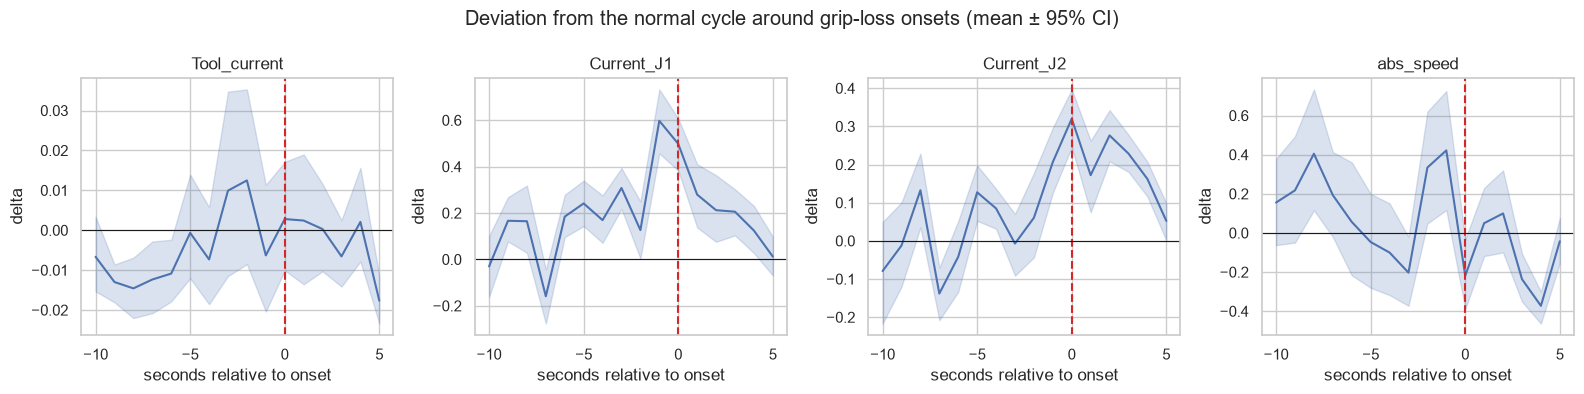

In [13]:
normal_profile = d[d["cycle_type"] == "normal"].groupby("pos")[SENSORS + ["abs_speed"]].mean()
df["abs_speed"] = df[SPD].abs().sum(axis=1)

def aligned(col, lags=range(-10, 6)):
    rows = []
    for i in np.where(df["onset"])[0]:
        for k in lags:
            j = i + k
            if 0 <= j < len(df) and df.at[j, "segment"] == df.at[i, "segment"]:
                ref = normal_profile[col].get(df.at[j, "pos"], np.nan)
                rows.append({"lag": k, "delta": df.at[j, col] - ref})
    return pd.DataFrame(rows)

fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharex=True)
for ax, col in zip(axes, ["Tool_current", "Current_J1", "Current_J2", "abs_speed"]):
    sns.lineplot(data=aligned(col), x="lag", y="delta", errorbar=("ci", 95), ax=ax)
    ax.axvline(0, color="tab:red", ls="--"); ax.axhline(0, color="k", lw=.8)
    ax.set_title(col); ax.set_xlabel("seconds relative to onset")
fig.suptitle("Deviation from the normal cycle around grip-loss onsets (mean ± 95% CI)")
plt.tight_layout(); plt.show()

**Reading:** x = 0 is the first second of the grip loss; above 0 means "higher than usual at this position of the cycle"; if the 95 % band does not touch 0, the deviation is significant.
- **Current_J1** is above normal from about **−6 s**, with a peak at **−1 s** (≈ +0.6 A), and stays high afterwards: the clearest precursor;
- **Current_J2** rises at −2/−1 s and peaks at the onset;
- **Tool_current**: noisy, the band touches 0 almost everywhere, no signal;
- **abs_speed**: irregular, a peak at −1 s then a drop at 0 (the robot slows down or stops when the loss happens).

The same computation on all six currents (in standard deviations) confirms that J1 is the only steady precursor, J2 the second, and J5 also reacts at −1 s and at the onset; J0, J3 and J4 show nothing consistent. This matches the mechanics: the shoulder (J1) and the elbow (J2) carry the weight of the part.

*Implications:* precursors exist but are **short** (1–2 s for the strongest), which suggests a horizon **N of 2 to 5 s** and window features over the last ~5 s, expressed as deviations from the normal profile (computed on the training set only). Caution: the bands are wide (77 events); since losses come in bursts (section 7), part of the "before" deviation may come from a previous loss in the same cycle; and the label may switch to 1 slightly after the physical event. If performance collapses from N = 2, the model only sees the loss itself.

## 7. Events: duration, spacing, events per cycle

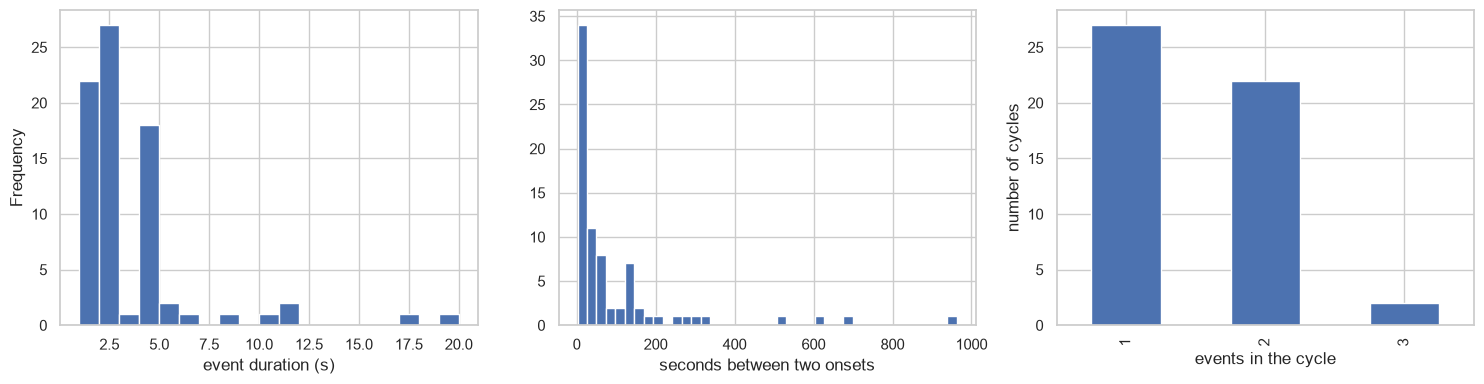

77 events, median duration 2 s, 6 pairs of onsets ≤ 10 s apart


In [14]:
ev = df[df["GL"] == 1].groupby("event_id").agg(duration=("GL", "size"), cycle_id=("cycle_id", "first"))
gaps = np.diff(np.where(df["onset"])[0])
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ev["duration"].plot.hist(bins=range(1, 21), ax=axes[0]); axes[0].set_xlabel("event duration (s)")
axes[1].hist(gaps, bins=40); axes[1].set_xlabel("seconds between two onsets")
ev.groupby("cycle_id").size().value_counts().sort_index().plot.bar(ax=axes[2])
axes[2].set_xlabel("events in the cycle"); axes[2].set_ylabel("number of cycles")
plt.tight_layout(); plt.show()
print(f"{len(ev)} events, median duration {ev['duration'].median():.0f} s, "
      f"{(gaps <= 10).sum()} pairs of onsets ≤ 10 s apart")

**Reading:**
- *duration*: most grip losses last 1–2 s (49 of 77 events), a group lasts 4 s, and 5 events last 10 s or more;
- *spacing*: 41 of the 76 gaps between consecutive onsets are ≤ 30 s (median 28 s), i.e. the next loss often happens in the same or the next cycle;
- *per cycle*: 27 cycles have 1 grip loss, **22 have 2**, 2 have 3.

*Implications:* **grip losses come in bursts**: once a loss happens, another one is likely soon (badly placed part, gripper drifting...). This gives a legitimate past-only feature, **time since the last grip loss** (or number of losses in the last cycles). It also means that events are not independent: confidence intervals must be computed with a **bootstrap over cycles**, and we must decide whether two onsets 3 s apart are one event or two.

## 8. Protective stops vs grip losses

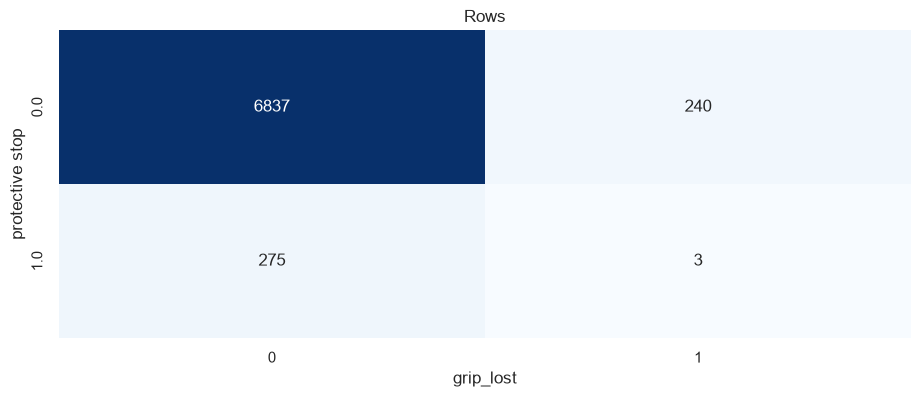

Cycles:
 gl     0   1
ps          
0.0  134  30
1.0   64  21
Fisher exact test p-value: 0.249


In [15]:
tab = pd.crosstab(d["PS"], d["GL"])
sns.heatmap(tab, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.xlabel("grip_lost"); plt.ylabel("protective stop"); plt.title("Rows")
plt.show()

cyc = df.groupby("cycle_id").agg(gl=("GL", "max"), ps=("PS", "max"))
ct = pd.crosstab(cyc["ps"], cyc["gl"])
print("Cycles:\n", ct)
print("Fisher exact test p-value:", round(stats.fisher_exact(ct)[1], 3))

**Reading:** only **3 rows** have both a protective stop and a grip loss, out of 278 protective-stop rows and 243 grip-loss rows. At the cycle level, cycles with a protective stop do not have significantly more grip losses (Fisher exact test p = 0.25).

*Implications:* the two faults are unrelated in this dataset: `Robot_ProtectiveStop` is **excluded** from the inputs. This also questions studies that merge both faults into a single label (Liu, 2025): they mix two different phenomena.

## 9. Missing rows and their effect on events

54 empty rows, in 53 cycles
events before dropping: 77, after dropping: 74


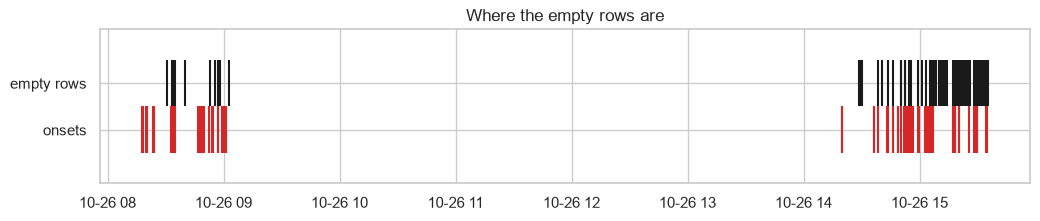

In [16]:
miss = df.index[df["nan_row"]]
print(f"{len(miss)} empty rows, in {df.loc[miss, 'cycle_id'].nunique()} cycles")
events_before = df["onset"].sum()
g = df.loc[~df["nan_row"], "GL"].reset_index(drop=True)
events_after = ((g == 1) & (g.shift(fill_value=0) == 0)).sum()
print(f"events before dropping: {events_before}, after dropping: {events_after}")

plt.figure(figsize=(12, 2))
plt.eventplot([df.loc[miss, "ts"]], colors="k", lineoffsets=1)
plt.eventplot([df.loc[df["onset"], "ts"]], colors="tab:red", lineoffsets=0)
plt.yticks([0, 1], ["onsets", "empty rows"]); plt.title("Where the empty rows are")
plt.show()

**Reading:**
- dropping the 54 empty rows **glues neighbouring events together** (77 → 74 events);
- the empty rows are mostly in the **afternoon** (44 of 54, while the afternoon holds 61 % of the rows);
- they are only slightly closer to grip-loss onsets than chance would give (28 % are within 10 s of an onset, vs 18 % expected), and not closer to protective stops at all; none of them is a grip-loss row.

*Implications:* there is **no strong evidence** that the missing rows are caused by the faults, but they are not evenly spread over time. They should be treated as **breaks** in the series (no lag or window across them, never predicted) rather than imputed with averages or silently removed.

## Summary of the relations
1. **One day, two sessions**: limited generalisation; never compute windows across the break.
2. **Time / temperature confounding**: grip losses are much more frequent during the cold start; temperatures look predictive mainly because of that.
3. **Temperatures are redundant** (r ≥ 0.99): keep one.
4. **During** a loss, loads change strongly (J1/J2) → consequences, leakage risk → predict before the onset.
5. **Cycle position** is a strong predictor (two risky phases: 3–5 s and 15–21 s) → mandatory baseline.
6. **Precursors exist but are short**: currents J1/J2 (and J5) deviate 1–6 s before the onset relative to the normal cycle → horizon of a few seconds, features relative to the cycle position.
7. **Grip losses come in bursts** (22 cycles with 2 losses) → "time since last loss" feature; bootstrap over cycles.
8. `Tool_current` alone does not separate the classes; `Robot_ProtectiveStop` is unrelated to grip losses.